## 1. Load Data & Preprocessing Dasar
**Tujuan:** Memuat dataset mentah dan membersihkan kolom yang masih berupa teks bersatuan (seperti "8GB" dan "1.37kg") menjadi numerik.
**Alasan:** Algoritma K-Means hanya bisa menghitung jarak Euclidean pada data numerik, sehingga teks harus dikonversi. Selain itu, kolom gabungan (Memory, CPU, ScreenResolution) diekstrak menjadi fitur-fitur terpisah agar informasinya lebih kaya.

In [8]:
import pandas as pd
import numpy as np
import re

# 1. Load data
df = pd.read_csv('laptop_price.csv', encoding='latin-1')
df.columns = df.columns.str.strip()

# 2. Bersihkan RAM & Weight
df['Ram_GB'] = pd.to_numeric(df['Ram'].astype(str).str.replace('GB', '', regex=False).str.strip(), errors='coerce')
df['Ram_GB'] = df['Ram_GB'].fillna(df['Ram_GB'].median()).astype(int)

df['Weight_kg'] = pd.to_numeric(df['Weight'].astype(str).str.replace('kg', '', regex=False).str.strip(), errors='coerce')
df['Weight_kg'] = df['Weight_kg'].fillna(df['Weight_kg'].median())

# 3. Bersihkan Memory (Pecah jadi Storage, SSD, HDD)
def parse_memory(mem):
    mem = str(mem)
    total_gb = 0.0
    for val, unit in re.findall(r'(\d+\.?\d*)\s*(GB|TB)', mem):
        v = float(val)
        total_gb += v * 1024 if unit == 'TB' else v
    has_ssd = 1 if 'SSD' in mem else 0
    has_hdd = 1 if 'HDD' in mem else 0
    return total_gb, has_ssd, has_hdd

df[['Storage_GB', 'Has_SSD', 'Has_HDD']] = df['Memory'].apply(lambda x: pd.Series(parse_memory(x)))

# 4. Bersihkan CPU (Ambil GHz)
def parse_cpu(cpu):
    m = re.search(r'(\d+\.?\d*)\s*GHz', str(cpu))
    return float(m.group(1)) if m else np.nan
df['CPU_GHz'] = df['Cpu'].apply(parse_cpu)
df['CPU_GHz'] = df['CPU_GHz'].fillna(df['CPU_GHz'].median())

# 5. Bersihkan ScreenResolution (Pecah jadi Touchscreen, IPS, Res_W, Res_H)
def parse_screen(res):
    res = str(res)
    touch = 1 if 'Touchscreen' in res else 0
    ips = 1 if 'IPS' in res else 0
    m = re.search(r'(\d+)x(\d+)', res)
    w, h = (int(m.group(1)), int(m.group(2))) if m else (0, 0)
    return touch, ips, w, h

df[['Touchscreen', 'IPS', 'Res_W', 'Res_H']] = df['ScreenResolution'].apply(lambda x: pd.Series(parse_screen(x)))

print("Semua fitur hasil pecahan berhasil dibuat!")

Semua fitur hasil pecahan berhasil dibuat!


## 2. Varian 1: Penentuan Jumlah Klaster (Metode Elbow)
**Tugas:** Ashfahani Hasyim (Anggota 1)
**Tujuan:** Menentukan jumlah klaster (k) yang paling optimal.
**Proses:**
1. Memilih 9 fitur sesuai kesepakatan proposal.
2. Melakukan `StandardScaler` karena K-Means sensitif terhadap perbedaan skala (wajib sesuai panduan PPT Hal. 13).
3. Melakukan perulangan (looping) K-Means untuk k=2 sampai k=10, dan menghitung nilai Inertia (WCSS).
**Kesimpulan:** Dari grafik yang dihasilkan, titik siku (elbow) berada di **k = 4**. Ini berarti 4 adalah jumlah klaster yang paling optimal untuk segmentasi laptop ini.

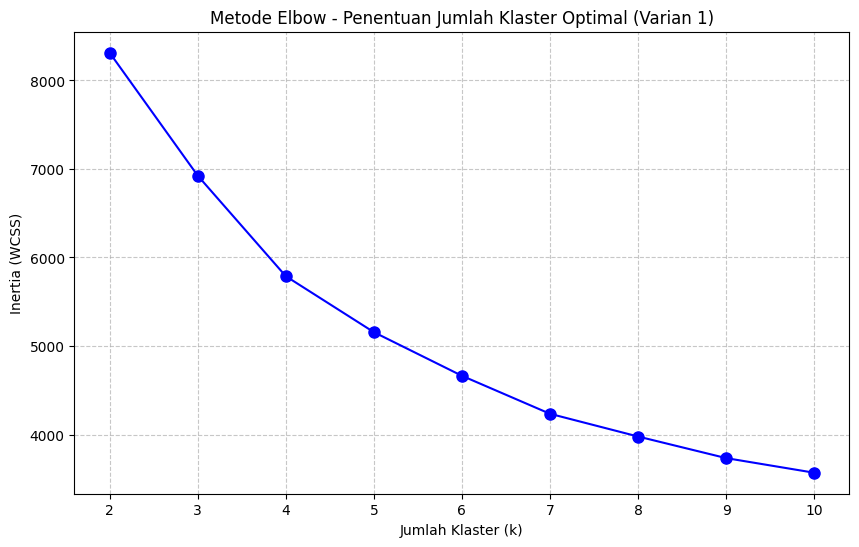

In [9]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Pilih fitur SESUAI PROPOSAL BARU
fitur = [
    'Inches', 'Ram_GB', 'Weight_kg', 'CPU_GHz',
    'Storage_GB', 'Has_SSD', 'Has_HDD', 'Touchscreen', 'IPS'
]
X = df[fitur]

# 2. Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Looping Elbow
inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# 4. Plot Grafik
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b', markersize=8)
plt.title('Metode Elbow - Penentuan Jumlah Klaster Optimal (Varian 1)')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Kesimpulan Varian 1:
Berdasarkan grafik Elbow di atas, penurunan Inertia sangat tajam dari k=2 hingga k=4, lalu mulai melandai setelah k=4.
Oleh karena itu, jumlah klaster (k) yang dipilih untuk tahap selanjutnya adalah **k = 4**.